In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0" # whatever is free
# os.environ["JAX_PLATFORM_NAME"] = "cpu"
# os.environ["JAX_LOG_COMPILES"] = "1" # to see jit compiliation triggers

from loguru import logger
import jax
logger.info(f'JAX is using: {jax.devices()}')

2026-05-18 13:25:29.367 | INFO     | __main__:<module>:8 - JAX is using: [CudaDevice(id=0)]


In [3]:
from pathlib import Path
from datetime import datetime
import wandb

from tqdm.auto import tqdm
import numpy as np
import jax.random as jr
import jax.numpy as jnp

from apa.utils.config import load_config
from apa.utils.env import load_and_replicate_levels, get_random_envs, make_env_from_config
from apa.repo import RandomMatchingRepo, ConstantMatchingRepo, PixelMatchingRepo

In [4]:
config_folder = Path('../third_party/kinetix/configs')
assert config_folder.exists()
config = load_config(config_path=str(config_folder),config_name='naive_repo')

rng = jax.random.PRNGKey(config.get('seed',0))

In [5]:
USE_WANDB = config['use_wandb']

run_folder_name = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")

if USE_WANDB:
    wandb_run = wandb.init(
        project="Naive Skill Repo", 
        config=dict(config)
    )

    wandb.define_metric("repo_step")
    # wandb.define_metric("pick_rate/*", step_metric="repo_step")
    wandb.define_metric("videos/*", step_metric="repo_step")
    wandb.define_metric("solve_rate/*", step_metric="repo_step")
    wandb.define_metric("ep_length/*", step_metric="repo_step")
    wandb.define_metric("ep_return/*", step_metric="repo_step")

    output_path = Path('outputs') / f'{run_folder_name}_{wandb_run.id}'
    
else:
    output_path = Path('outputs') / run_folder_name

output_path.mkdir(parents=True, exist_ok=False)

In [6]:
# Env spawning

if config["train_level_mode"] == "random":
    rng, sub_rng = jr.split(rng)
    env, env_params, static_env_params = make_env_from_config(config)
    env_reset_states = get_random_envs(config["num_train_envs"], config["num_copies_per_env"], env, env_params, sub_rng)
else:
    env_reset_states = load_and_replicate_levels(
        config["train_levels_list"],
        int(config["num_copies_per_env"]),
    )
    config["num_train_envs"] = len(config["train_levels_list"])

Created static_env_params=StaticEnvParams(num_polygons=5, num_circles=2, num_joints=1, num_thrusters=1, max_polygon_vertices=4, num_solver_iterations=10, solver_batch_size=16, do_warm_starting=True, num_static_fixated_polys=4, screen_dim=(500, 500), downscale=4, frame_skip=2, max_shape_size=2, num_motor_bindings=4, num_thruster_bindings=2) when loading evaluation levels.


In [ ]:
# num_repo_updates = int(config['num_repo_updates'])
num_repo_updates = 2
random_policy_repo = RandomMatchingRepo(config, env_reset_states, rng)
for repo_update_idx in tqdm(range(num_repo_updates)):
    random_policy_repo.advance()

random_repo_eval_matrics = [random_policy_repo.evaluate() for _ in range(5)]
random_repo_eval_matrics = jnp.mean(jnp.stack(random_repo_eval_matrics), axis = 0)
random_repo_eval_matrics = np.array(random_repo_eval_matrics)

  0%|          | 0/2 [00:00<?, ?it/s]

PPO Updates...:   0%|          | 0/100 [00:00<?, ?it/s]

PPO Updates...:   0%|          | 0/100 [00:00<?, ?it/s]

In [ ]:
# num_repo_updates = int(config['num_repo_updates'])
num_repo_updates = 2
pm_policy_repo = PixelMatchingRepo(config, env_reset_states, rng, env_pool_size=5, history_window=5, policy_success_threshold=0.5)
for repo_update_idx in tqdm(range(num_repo_updates)):
    pm_policy_repo.advance()

pm_repo_eval_matrics = [pm_policy_repo.evaluate() for _ in range(5)]
pm_repo_eval_matrics = jnp.mean(jnp.stack(pm_repo_eval_matrics), axis = 0)
pm_repo_eval_matrics = np.array(pm_repo_eval_matrics)

  0%|          | 0/2 [00:00<?, ?it/s]

PPO Updates...:   0%|          | 0/100 [00:00<?, ?it/s]

PPO Updates...:   0%|          | 0/100 [00:00<?, ?it/s]

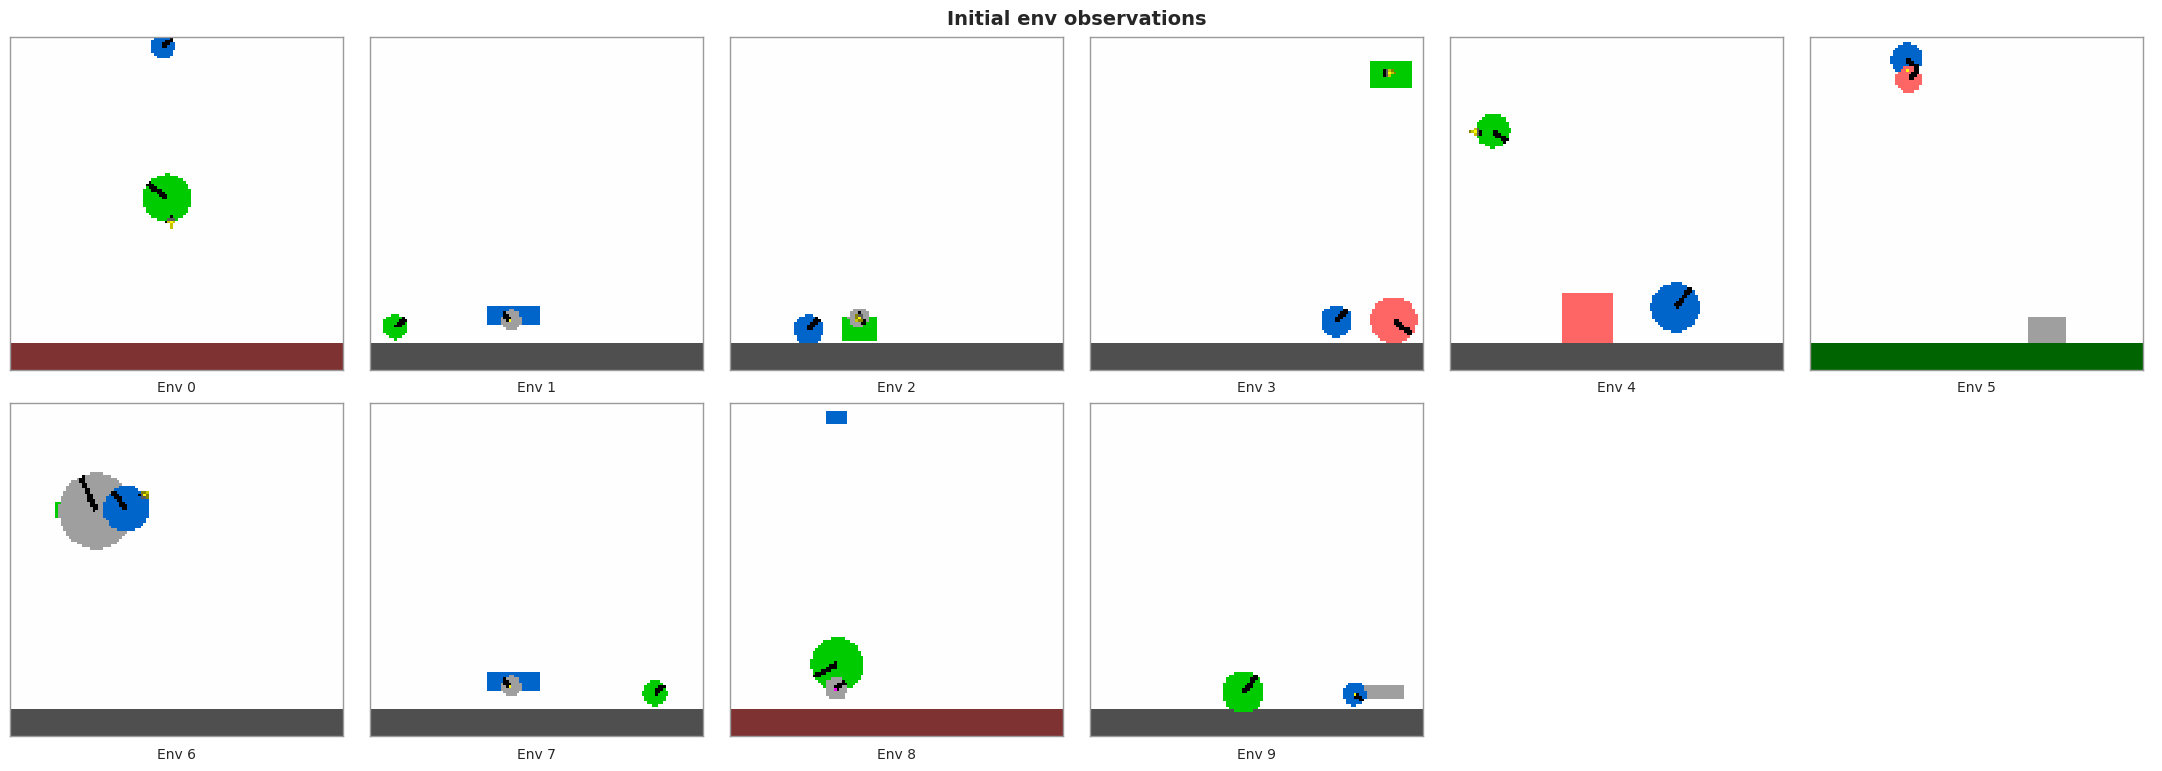

In [52]:
from apa.utils.log import plot_env_pixel_grid
import matplotlib.pyplot as plt

initial_pixel_obs = np.array(pm_policy_repo.initial_pixel_obs)
plot_env_pixel_grid(initial_pixel_obs, cols=6, title="Initial env observations")
plt.show()

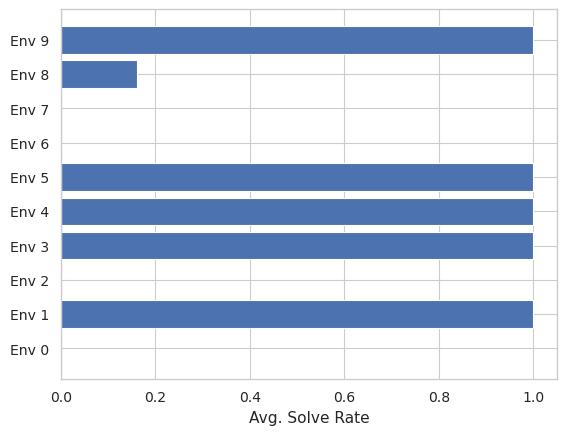

In [64]:
plt.barh([f'Env {i}' for i in range(pm_repo_eval_matrics.shape[0])],
        pm_repo_eval_matrics[:,0])
plt.xlabel('Avg. Solve Rate')
plt.show()

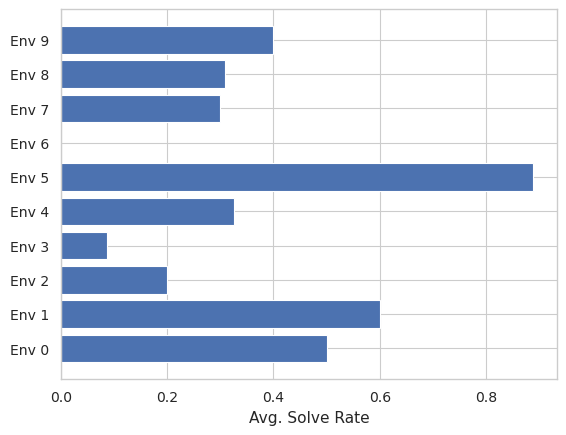

In [66]:
plt.barh([f'Env {i}' for i in range(random_repo_eval_matrics.shape[0])],
        random_repo_eval_matrics[:,0])
plt.xlabel('Avg. Solve Rate')
plt.show()

In [8]:
# num_repo_updates = int(config['num_repo_updates'])
# policy_repo = ConstantMatchingRepo(config, env_reset_states, rng)
# for repo_update_idx in tqdm(range(num_repo_updates)):
#     policy_repo.advance()

In [ ]:
# TODO:
# oracle
# option to load from the checkpoint path
# solving the problem of of stagnation (some envs not getting picked)
# problem with low number of environments: the distance zero is always getting chosen
# reverse: forcing envs into policies => maybe policy doesn't want it (not my problem)

In [11]:
# import pickle

# with open(output_path / 'skill_repo_perf.pkl', 'wb') as file:
#     pickle.dump(repo_full_perf_history, file)

# # with open(output_path / 'skill_repo_perf.pkl', 'rb') as file:
# #     repo_full_perf_history = pickle.load(file)